# Prepare the battery data

Combine the processed battery files, check the data, and save the master table.

## Dataset

Each row is one battery cycle. `RUL` is the target in cycles. `battery_id` identifies the physical cell.

In [5]:
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

# Locate the project root whether the notebook runs from the repo or notebooks/.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "Datasets").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

SOURCE_DIR = PROJECT_ROOT / "Datasets" / "HNEI_Processed"
MASTER_PATH = PROJECT_ROOT / "Datasets" / "Battery_RUL_Master.csv"
source_files = sorted(SOURCE_DIR.glob("HNEI_*_features.csv"))

print(f"Project root: {PROJECT_ROOT}")
print(f"Processed battery files found: {len(source_files)}")
assert len(source_files) == 14, "The project should contain 14 processed battery files."

FEATURE_COLUMNS = [
    "Discharge Time (s)",
    "Decrement 3.6-3.4V (s)",
    "Max. Voltage Dischar. (V)",
    "Min. Voltage Charg. (V)",
    "Time at 4.15V (s)",
    "Time constant current (s)",
    "Charging time (s)",
]
EXPECTED_COLUMNS = ["Cycle_Index", "battery_id", *FEATURE_COLUMNS, "RUL"]

# The script owns only the repeatable file-combining step.
subprocess.run(
    [sys.executable, str(PROJECT_ROOT / "src" / "preprocess.py")],
    cwd=PROJECT_ROOT,
    check=True,
)

Project root: /home/jayanth/CODE/projects/Battery_RUL_Prediction
Processed battery files found: 14
Saved 15,064 rows for 14 batteries to Datasets/Battery_RUL_Master.csv


CompletedProcess(args=['/home/jayanth/miniconda3/envs/ml-core/bin/python', '/home/jayanth/CODE/projects/Battery_RUL_Prediction/src/preprocess.py'], returncode=0)

## 1. Inspect source files

In [6]:
master = pd.read_csv(MASTER_PATH)
print(f"Master dataset shape: {master.shape[0]:,} rows x {master.shape[1]} columns")
master.head()

Master dataset shape: 15,064 rows x 10 columns


,Cycle_Index,battery_id,Discharge Time (s),Decrement 3.6-3.4V (s),Max. Voltage Dischar. (V),Min. Voltage Charg. (V),Time at 4.15V (s),Time constant current (s),Charging time (s),RUL
0,1.0,HNEI_a,2595.30,1151.488500,3.670,3.211,5460.001,6755.01,10777.82,1112
1,2.0,HNEI_a,7408.64,1172.512500,4.246,3.220,5508.992,6762.02,10500.35,1111
2,3.0,HNEI_a,7393.76,1112.992000,4.249,3.224,5508.993,6762.02,10420.38,1110
3,4.0,HNEI_a,7385.50,1080.320667,4.250,3.225,5502.016,6762.02,10322.81,1109
4,6.0,HNEI_a,65022.75,29813.487000,4.290,3.398,5480.992,53213.54,56699.65,1107


In [7]:
source_summary = []

for file_path in source_files:
    battery = pd.read_csv(file_path)
    battery = battery.loc[:, ~battery.columns.astype(str).str.startswith("Unnamed")]

    source_summary.append(
        {
            "battery_file": file_path.name,
            "rows": len(battery),
            "columns": len(battery.columns),
            "missing_values": int(battery.isna().sum().sum()),
            "first_cycle": battery["Cycle_Index"].min(),
            "last_cycle": battery["Cycle_Index"].max(),
        }
    )

source_summary = pd.DataFrame(source_summary).sort_values("battery_file")
source_summary

,battery_file,rows,columns,missing_values,first_cycle,last_cycle
0,HNEI_a_features.csv,1076,10,0,1.0,1113.0
1,HNEI_b_features.csv,1079,10,0,1.0,1108.0
2,HNEI_c_features.csv,1077,10,0,1.0,1108.0
3,HNEI_d_features.csv,1081,10,0,1.0,1108.0
4,HNEI_e_features.csv,1077,10,0,1.0,1134.0
5,HNEI_f_features.csv,1078,10,0,1.0,1103.0
6,HNEI_g_features.csv,1081,10,0,1.0,1108.0
7,HNEI_j_features.csv,1080,10,0,1.0,1105.0
8,HNEI_l_features.csv,1079,10,0,1.0,1108.0
9,HNEI_n_features.csv,1079,10,0,1.0,1108.0


## 2. Load the master table

In [8]:
battery_profile = (
    master.groupby("battery_id")
    .agg(
        rows=("battery_id", "size"),
        first_cycle=("Cycle_Index", "min"),
        last_cycle=("Cycle_Index", "max"),
        final_rul=("RUL", "min"),
    )
    .sort_index()
)

battery_profile

,rows,first_cycle,last_cycle,final_rul
battery_id,,,,
HNEI_a,1076,1.0,1113.0,0
HNEI_b,1079,1.0,1108.0,0
HNEI_c,1077,1.0,1108.0,0
HNEI_d,1081,1.0,1108.0,0
HNEI_e,1077,1.0,1134.0,0
HNEI_f,1078,1.0,1103.0,0
HNEI_g,1081,1.0,1108.0,0
HNEI_j,1080,1.0,1105.0,0
HNEI_l,1079,1.0,1108.0,0


## 3. Battery coverage

In [9]:
assert master.columns.tolist() == EXPECTED_COLUMNS
assert master["battery_id"].nunique() == len(source_files)
assert master[EXPECTED_COLUMNS].notna().all().all()

master.describe().T

,count,mean,std,min,25%,50%,75%,max
Cycle_Index,15064.0,556.155005,322.378480,1.000,271.000000,560.000000,833.0000,1134.000
Discharge Time (s),15064.0,4581.273960,33144.012077,8.690,1169.310000,1557.250000,1908.0000,958320.370
Decrement 3.6-3.4V (s),15064.0,1239.784672,15039.589269,-397645.908,319.600000,439.239471,600.0000,406703.768
Max. Voltage Dischar. (V),15064.0,3.908176,0.091003,3.043,3.846000,3.906000,3.9720,4.363
Min. Voltage Charg. (V),15064.0,3.577904,0.123695,3.022,3.488000,3.574000,3.6630,4.379
Time at 4.15V (s),15064.0,3768.336171,9129.552477,-113.584,1828.884179,2930.203500,4088.3265,245101.117
Time constant current (s),15064.0,5461.266970,25155.845202,5.980,2564.310000,3824.260000,5012.3500,880728.100
Charging time (s),15064.0,10066.496204,26415.354121,5.980,7841.922500,8320.415000,8763.2825,880728.100
RUL,15064.0,554.194172,322.434514,0.000,277.000000,551.000000,839.0000,1133.000


## 4. Data checks

In [10]:
numeric_columns = ["Cycle_Index", *FEATURE_COLUMNS, "RUL"]

assert master[numeric_columns].apply(pd.api.types.is_numeric_dtype).all()
assert master[numeric_columns].notna().all().all()
assert not master.duplicated(["battery_id", "Cycle_Index"]).any()
assert (master["Cycle_Index"] >= 0).all()
assert (master["RUL"] >= 0).all()
assert battery_profile["first_cycle"].le(battery_profile["last_cycle"]).all()

quality_summary = pd.Series(
    {
        "rows": len(master),
        "batteries": master["battery_id"].nunique(),
        "duplicate battery-cycle rows": int(master.duplicated(["battery_id", "Cycle_Index"]).sum()),
        "missing values": int(master.isna().sum().sum()),
    }
)
quality_summary

rows                            15064
batteries                          14
duplicate battery-cycle rows        0
missing values                      0
dtype: int64

## 5. Quick plots

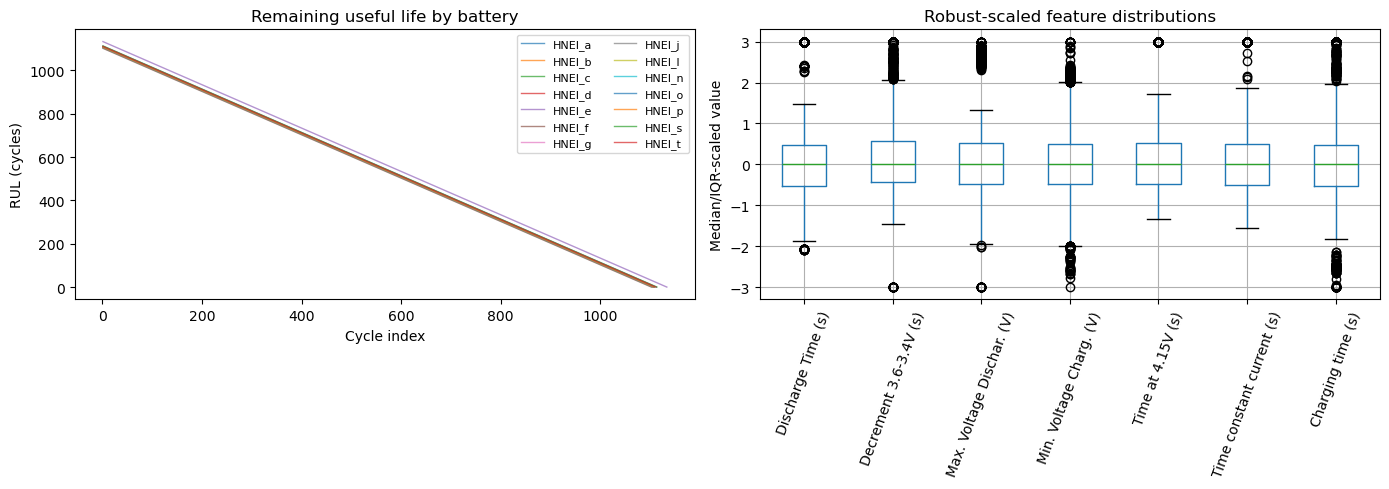

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for battery_id, battery_data in master.groupby("battery_id"):
    axes[0].plot(
        battery_data["Cycle_Index"],
        battery_data["RUL"],
        alpha=0.7,
        linewidth=1,
        label=battery_id,
    )

axes[0].set_title("Remaining useful life by battery")
axes[0].set_xlabel("Cycle index")
axes[0].set_ylabel("RUL (cycles)")
axes[0].legend(ncol=2, fontsize=8)

feature_medians = master[FEATURE_COLUMNS].median()
feature_iqr = master[FEATURE_COLUMNS].quantile(0.75) - master[FEATURE_COLUMNS].quantile(0.25)
robust_features = (master[FEATURE_COLUMNS] - feature_medians) / feature_iqr
robust_features = robust_features.clip(-3, 3)
robust_features.boxplot(ax=axes[1], rot=70)
axes[1].set_title("Robust-scaled feature distributions")
axes[1].set_ylabel("Median/IQR-scaled value")

plt.tight_layout()

## Output

Saved to `Datasets/Battery_RUL_Master.csv`.